In [1]:
#Import Pandas, Matplotlib, and Numpy Libraries 
import pandas as pd
import matplotlib.pyplot as plt 
import numpy as np

In [ ]:
#Import CSV file into a Pandas DataFrame 
Inflation_Data = pd.read_csv("STATIC_INFLATIONCALC.csv", skiprows=8)


#Convert the date column to datetimes and use it as the index so months can be looked up by date
Inflation_Data["date"] = pd.to_datetime(Inflation_Data["date"])
Inflation_Data = Inflation_Data.set_index("date")

#Create NumPy arrays: dates truncated to month precision, and the CPI values
DATES = Inflation_Data.index.values.astype("datetime64[M]")
CPI = Inflation_Data["STATIC_INFLATIONCALC"].to_numpy(dtype=float)

#Display the data
display(Inflation_Data)




,STATIC_INFLATIONCALC
date,
1914-01-01,6.0
1914-02-01,6.0
1914-03-01,6.0
1914-04-01,6.0
1914-05-01,5.9
...,...
2026-05-01,169.6
2026-06-01,169.0
2026-07-01,169.9


In [ ]:

class Inflation_Calculator:

## Store the user's inputs: the price and the first and second period as month-precision dates
    def __init__(self, price, start_year, start_month, end_year, end_month):
        self.price = price
        self.start = np.datetime64(f"{start_year}-{start_month:02d}")
        self.end = np.datetime64(f"{end_year}-{end_month:02d}")

# Look up the CPI for a given month using a binary search on the sorted dates
    def get_cpi(self, date):
        i = np.searchsorted(DATES, date)
        if i == len(DATES) or DATES[i] != date:
            raise ValueError(f"No CPI data for {date}")
        return CPI[i]
    
# Return the CPI for the first and second period
    def CPI_Calculation(self):
        return self.get_cpi(self.start), self.get_cpi(self.end)

 # Convert the price from the first period to the second: Cost2 = Cost1 * (CPI2 / CPI1)
    def Inflation_Adjusted_Price_Calculation(self):
        start_cpi, end_cpi = self.CPI_Calculation()
        return self.price * (end_cpi / start_cpi)

 # Calculate how many dollars the price changed by
    def Dollar_Change_Calculation(self):
        return self.Inflation_Adjusted_Price_Calculation() - self.price
    
# Calculate the average annual rate of inflation (compound annual growth rate of the CPI)
    def Average_Annual_Inflation_Calculation(self):
        start_cpi, end_cpi = self.CPI_Calculation()
        years = self.number_of_years_calculation()
        if years == 0:
            return 0.0  
        return ((end_cpi / start_cpi) ** (1 / years) - 1) * 100

 # Calculate the number of years between the two dates (subtracting months gives whole months)
    def number_of_years_calculation(self):
        # Subtracting datetime64[M] values gives whole months
        return (self.end - self.start).astype(int) / 12

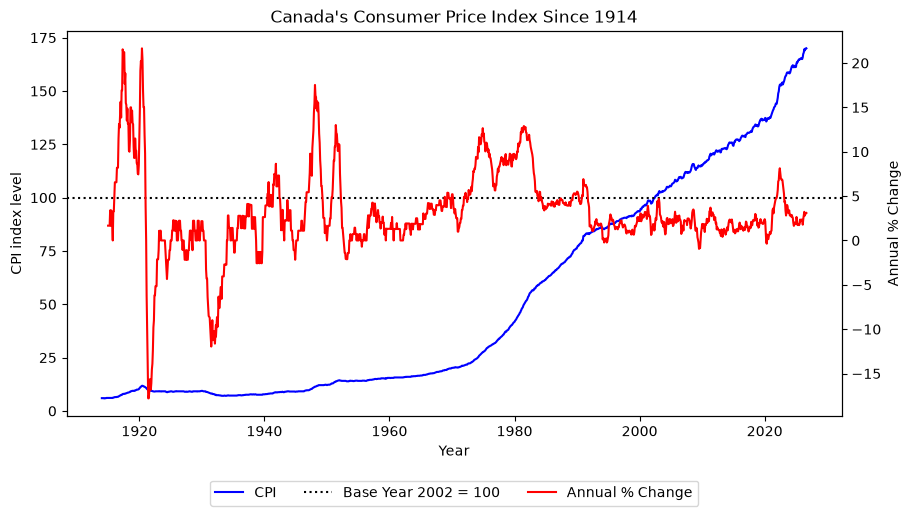

In [ ]:
# Create the figure and plot the CPI level on the left axis
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(DATES, CPI, color="blue", label="CPI")

# Add a reference line at the base year (2002 = 100)
ax.axhline(100, color="black", linestyle=":", label="Base Year 2002 = 100")

# Label the axes and add a title
ax.set_xlabel("Year")
ax.set_ylabel("CPI index level")
ax.set_title("Canada's Consumer Price Index Since 1914"

# Calculate the annual % change by comparing each month to the same month 12 months earlier
yoy = np.full(CPI.shape, np.nan)
yoy[12:] = (CPI[12:] / CPI[:-12] - 1) * 100

# Plot the annual % change on a second y-axis on the right
ax2 = ax.twinx()
ax2.plot(DATES, yoy, color="red", label="Annual % Change")
ax2.set_ylabel("Annual % Change")

# Combine both axes' legends into one and place it below the chart
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)

# Save the chart 
fig.savefig("cpi_chart.png", dpi=300, bbox_inches="tight")

In [ ]:
# Find the first and last year and month in the dataset to use as input limits
first_year = Inflation_Data.index.min().year
first_month = Inflation_Data.index.min().month
last_year = Inflation_Data.index.max().year
last_month = Inflation_Data.index.max().month

# Ask for the price and keep asking until it is a number greater than 0
while True:
    try:
        price = float(input("Enter the price of the good or service: $"))
        if price > 0:
            break
        print("Price must be greater than 0.")
    except ValueError:
        print("Invalid price. Enter a number, for example 25.50")

# Ask for the first period year and keep asking until it is inside the dataset's years
while True:
    try:
        start_year = int(input(f"Enter the first period year ({first_year}-{last_year}): "))
        if first_year <= start_year <= last_year:
            break
        print(f"Year must be between {first_year} and {last_year}.")
    except ValueError:
        print("Invalid year. Enter a whole number, for example 1995")

# Ask for the first period month (1-12) and check it exists in the data for the first and last year
while True:
    try:
        start_month = int(input("Enter the first period month (1-12): "))
        if not 1 <= start_month <= 12:
            print("Month must be between 1 and 12.")
        elif start_year == first_year and start_month < first_month:
            print(f"Data starts in month {first_month} of {first_year}.")
        elif start_year == last_year and start_month > last_month:
            print(f"Data ends in month {last_month} of {last_year}.")
        else:
            break
    except ValueError:
        print("Invalid month. Enter a whole number from 1 to 12")

# Ask for the second period year and keep asking until it is inside the dataset's years
while True:
    try:
        end_year = int(input(f"Enter the second period year ({first_year}-{last_year}): "))
        if first_year <= end_year <= last_year:
            break
        print(f"Year must be between {first_year} and {last_year}.")
    except ValueError:
        print("Invalid year. Enter a whole number, for example 2024")

# Ask for the second period month (1-12) and check it exists in the data for the first and last year
while True:
    try:
        end_month = int(input("Enter the second period month (1-12): "))
        if not 1 <= end_month <= 12:
            print("Month must be between 1 and 12.")
        elif end_year == first_year and end_month < first_month:
            print(f"Data starts in month {first_month} of {first_year}.")
        elif end_year == last_year and end_month > last_month:
            print(f"Data ends in month {last_month} of {last_year}.")
        else:
            break
    except ValueError:
        print("Invalid month. Enter a whole number from 1 to 12")

# Print the inputs back to confirm what was entered
print(price, start_year, start_month, end_year, end_month)

Data ends in month 9 of 2026.
100.0 1914 1 2026 9


In [ ]:
# Create the calculator with the user's inputs
calc = Inflation_Calculator(price, start_year, start_month, end_year, end_month)

# Run each calculation
starting_cpi, ending_cpi = calc.CPI_Calculation()
adjusted_price = calc.Inflation_Adjusted_Price_Calculation()
dollar_change = calc.Dollar_Change_Calculation()
years = calc.number_of_years_calculation()
avg_annual_inflation = calc.Average_Annual_Inflation_Calculation()

# Print the results
print("\n--- Results ---")
print(f"${price:,.2f} in {start_month}/{start_year} is worth ${adjusted_price:,.2f} in {end_month}/{end_year}")
print(f"Number of years: {years:.2f}")
print(f"Average annual rate of inflation (%) / Decline in the value of money: {avg_annual_inflation:.2f}%")
print(f"CPI for first period: {starting_cpi:.2f}")
print(f"CPI for second period: {ending_cpi:.2f}")


--- Results ---
$100.00 in 1/1914 is worth $2,833.33 in 9/2026
Number of years: 112.67
Average annual rate of inflation (%) / Decline in the value of money: 3.01%
CPI for first period: 6.00
CPI for second period: 170.00
